*  DSC530-T301 Data Exploration and Analysis
*  Weeks 9 & 10 Coding Assignment
*  Ander (Trevor) McKee

## Setup and Environment Notes

For each exercise, I restate the problem, document **which functions I use and why**, show the code with step comments and its output, then share a few notes/observations about the results. This assignment covers Chapter 9 exercises **1(a, c–e)**, **2(a–e)**, and **3(a–e)**. Exercise 1 part (b) is an EDA step and is excluded from the assignment.

As in previous assignments, this file runs in the `pandas-book` environment that's set up with the textbook (Python 3.8, **pandas 1.2.0**, **scikit-learn 0.23.2**, **matplotlib 3.3.2**, **seaborn 0.11.2**). Two of the exercises call helper functions from `ml_utils`, which is the author's companion package installed from `requirements.txt` (`git+https://github.com/stefmolin/ml-utils.git@2nd_edition`).

**Function notes:**

- `%matplotlib inline` sets matplotlib's backend to inline, which renders each figure as a static PNG embedded directly under each cell. This helps keep images visible in the saved file. 

In [1]:
# Imports.
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn

# Confirm environment.
print(f"pandas version:       {pd.__version__}")
print(f"numpy version:        {np.__version__}")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"matplotlib version:   {matplotlib.__version__}")
print(f"seaborn version:      {sns.__version__}")

pandas version:       1.2.0
numpy version:        1.19.5
scikit-learn version: 0.23.2
matplotlib version:   3.3.2
seaborn version:      0.11.2


# Chapter 9, Exercise 1: Clustering Model

> Build a clustering model to distinguish between red and white wine by their chemical properties:
>
> **a.** Combine the red and white wine datasets (`data/winequality-red.csv` and `data/winequality-white.csv`, respectively) and add a column for the kind of wine (red or white).
>
> **c.** Build and fit a pipeline that scales the data and then uses k-means clustering to make two clusters. Be sure not to use the `quality` column.
>
> **d.** Use the Fowlkes-Mallows Index (the `fowlkes_mallows_score()` function is in `sklearn.metrics`) to evaluate how well k-means is able to make the distinction between red and white wine.
>
> **e.** Find the center of each cluster.

## Part (a): Combine the datasets and label the kind of wine

**Function notes:**
- `pd.read_csv()` needs to be called twice with different delimiters. The red file is comma-delimited, and the white file is semicolon-delimited with quoted headers.
- I use `.assign`, because it creates a new frame, and `(kind=...)` adds the label column inside the same expression.
- `pd.concat()` stacks the two frames vertically by aligning the same 12 columns across both.
- `ignore_index=True` renumbers the index. It's not actually necessary, but it's good practice if I wanted to use `.loc[]` or something.

In [2]:
# Red file is comma-delimited; white uses a semicolon.
red_wine = pd.read_csv("data/winequality-red.csv")
white_wine = pd.read_csv("data/winequality-white.csv", sep=";")

# Label the frames, then stack them.
wine = pd.concat(
    [white_wine.assign(kind="white"), red_wine.assign(kind="red")],
    ignore_index=True,
)

# Check the frame's structure.
print(f"red wine:   {red_wine.shape}")
print(f"white wine: {white_wine.shape}")
print(f"combined:   {wine.shape}")
print(f"columns match: {red_wine.columns.equals(white_wine.columns)}")
print(f"missing values: {wine.isna().sum().sum()}")
print(f"exact duplicate rows: {wine.duplicated().sum()}")
print()
print(wine.kind.value_counts())
wine.sample(5, random_state=10)

red wine:   (1599, 12)
white wine: (4898, 12)
combined:   (6497, 13)
columns match: True
missing values: 0
exact duplicate rows: 1177

white    4898
red      1599
Name: kind, dtype: int64


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,kind
5746,6.4,0.64,0.21,1.8,0.081,14.0,31.0,0.99689,3.59,0.66,9.8,5,red
2529,6.6,0.42,0.13,12.8,0.044,26.0,158.0,0.99772,3.24,0.47,9.0,5,white
5029,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.99370,3.63,0.63,13.0,5,red
5142,15.0,0.21,0.44,2.2,0.075,10.0,24.0,1.00005,3.07,0.84,9.2,7,red
1551,6.6,0.19,0.99,1.2,0.122,45.0,129.0,0.99360,3.09,0.31,8.7,6,white


**My notes:**
- The combined dataset is 6,497 rows and 13 columns: 11 chemical measurements, the `quality` score, and the `kind` label.
- There are 4,898 white wines and 1,599 red, so white makes up about 75% of the data.
- There are no missing values, which I thought was unusual. But it makes this an easier setup.
- There are 1,177 exact duplicate rows, and they're likely repeated records rather than actually different wines. Duplicate pairs are always close to each other in the dataset, with a median gap of 2 rows in the red file and 4 in the white. Not a single pair is more than 21 rows apart. If they were truly coincidental, they'd likely be scattered across the file, especially considering the file is not sorted on any column.
- Additionally, there's not a single instance of two entries with the same stats having different quality scores. For 1,177 duplicates, it would be absurd to imply they all happen to be rated the same yet still be unique wines.
- I left the duplicates in, because the textbook does. This means the index describes 6,497 records rather than 6,497 distinct wines.

## Part (c): Scale and cluster with a pipeline

**Function notes:**
- `StandardScaler()` converts each column to z-scores. You must standardize for k-means, because one large scale (*ahem* sulfur dioxide from 6 to 440) would dominate the calculation compared to small scales (like density from 0.987 to 1.039).
- `X = wine.drop(columns=["quality", "kind"])` drops `quality` as per the instructions (it's a human taste score), and `kind` is excluded because it's the answer.
- `train_test_split()` is used in the textbook solution, and I kept it so the Fowlkes-Mallows score is checkable against that file. However, I would say the split isn't required here. The model estimates 22 numbers (2 centroids × 11 features) from 4,872 wines, so there's very little to overfit. Additionally, in part (d), the test index score was higher than the training score, which is opposite to what would happen if your clustering overfit.
- `stratify=y` forces the white/red ratio in both halves to match the ratios of the full dataset.
- `Pipeline` chains the scaler and the model into one object, which makes the scaler fit on the **training data only**. Then, we can reapply those same means and standard deviations at predict time.
- `random_state=0` fixes the *centroid initialization* so the results are reproducible. By default, it runs 10 times and picks the best, so the seed matters less than it would with a single start.

In [3]:
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# y is only used for the split and for scoring.
y = wine.kind
X = wine.drop(columns=["quality", "kind"])

# stratify=y keeps the white/red ratio the same in both halves.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y
)

# Scale, then cluster into two.
kmeans_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=2, random_state=0)),
]).fit(X_train)

# Compare the size of each predicted cluster against the actual.
kmeans_preds = kmeans_pipeline.predict(X_test)
pd.DataFrame({
    "predicted cluster size": pd.Series(kmeans_preds).value_counts().sort_index().values,
    "actual kind count": y_test.value_counts().sort_index(ascending=False).values,
}, index=["cluster 0 / white", "cluster 1 / red"])

,predicted cluster size,actual kind count
cluster 0 / white,1211,1225
cluster 1 / red,414,400


**My notes:**
- The two cluster sizes (1,211 and 414) come out close to the actual counts of 1,225 white and 400 red. That's good, but matching sizes doesn't tell us the right wines are in each cluster. The crosstab in part (d) checks this.
- The cluster numbers of 0 and 1 are arbitrary and just happen to line up. Part (d) also does not care about the numbering.
- The pipeline object holds both fitted steps, so `kmeans_pipeline.predict()` scales the test data with the *training* means and standard deviations before clustering it.

## Part (d): Evaluate with the Fowlkes-Mallows Index

**Function notes:**
- `fowlkes_mallows_score(labels_true, labels_pred)` asks, for every pair of wines, whether the two groupings agree about whether that pair belongs together.
- It's the geometric mean of the pairwise precision and recall, so it lands in [0, 1] with 1 being perfect agreement:
$$ FMI = \frac{TP}{\sqrt{(TP + FP) \times (TP + FN)}} $$
- **TP** is pairs of wines that are the same type and were predicted in the same cluster; **FP** is pairs the model grouped together that are actually different types; **FN** is pairs that are the same type but the model split apart; **TN** is pairs that are different types and the model separated. The textbook solution file has the definitions of FP and FN swapped, but the calculation is the same.
- `np.where(y_test == "red", 0, 1)` is a vectorized if/else — it evaluates `y_test == "red"` to a boolean Series, then returns 0 where that's True and 1 everywhere else, as a NumPy integer array. It isn't required. I checked, and `fowlkes_mallows_score()` returns the same 0.9825 given the "red"/"white" strings, or 7 and 99, or any other pair of labels. I keep the conversion because it makes both arguments read as cluster labels of the same kind.
- The contrast is `accuracy_score(y_test, kmeans_preds)`, which fails with a TypeError on those same inputs.
- I add `pd.crosstab()` to see where they disagree. It's the same idea as a confusion matrix, just without the labels 0 and 1 meaning something.

In [4]:
from sklearn.metrics import fowlkes_mallows_score

# Convert to integers for readability
y_test_binary = np.where(y_test == "red", 0, 1)
fmi = fowlkes_mallows_score(y_test_binary, kmeans_preds)
print(f"Fowlkes-Mallows Index (test set): {fmi:.4f}")

# Sanity checks: the same score on the training data and on a refit of everything.
print(f"Fowlkes-Mallows Index (train set): "
      f"{fowlkes_mallows_score(np.where(y_train == 'red', 0, 1), kmeans_pipeline.predict(X_train)):.4f}")

full_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("kmeans", KMeans(n_clusters=2, random_state=0)),
]).fit(X)
print(f"Fowlkes-Mallows Index (all 6,497): "
      f"{fowlkes_mallows_score(np.where(y == 'red', 0, 1), full_pipeline.predict(X)):.4f}")

# Where does it disagree?
pd.crosstab(y_test, kmeans_preds, rownames=["actual kind"], colnames=["assigned cluster"])

Fowlkes-Mallows Index (test set): 0.9825
Fowlkes-Mallows Index (train set): 0.9742
Fowlkes-Mallows Index (all 6,497): 0.9775


assigned cluster,0,1
actual kind,,
red,2,398
white,1209,16


**My notes:**
- The index is **0.9825**, so k-means separates red from white almost perfectly using just chemistry.
- FMI, however, is not corrected for chance. Shuffling predictions randomly would get an index of 0.624, and putting every wine in a single cluster would give you 0.793. Adjusted Rand Index (ARI) would score the model more honestly, but FMI is used as per the instructions.
- The crosstab shows only 18 of the 1,625 test wines land in the wrong group. Whites are the ones that got misplaced (16 of 18), which makes sense given there are thrice as many white wines.
- The score is stable across the training set (0.9742) and a refit on all 6,497 rows (0.9775).
- A high FMI means the two clusters correspond to red and white. It doesn't mean k-means "knows" what wine is. If red and white happened to overlap chemically, this code could produce two clusters with a poor index.

## Part (e): Find the center of each cluster

**Function notes:**
- `kmeans_pipeline.named_steps["kmeans"]` grabs the fitted `KMeans` object from the pipeline, then `.cluster_centers_` returns the centroids as a 2-by-11 array.
- Those centroids are scaled in units of standard deviations from the mean. This is the textbook solution, and it's what you look at to determine which features drove the split.
- `named_steps["scale"].inverse_transform()` converts the centroids back to original units (g/L, mg/L, % alcohol). These columns are useful if you want to describe a cluster to someone.
- `.T` just transposes, so the features are rows.
- I put the true group means next to the centers to check. If the clusters are actually red and white, they should be very similar.

In [5]:
# Pull the steps out of the pipeline.
kmeans_step = kmeans_pipeline.named_steps["kmeans"]
scaler_step = kmeans_pipeline.named_steps["scale"]

# Centers as per the algorithm.
centers_scaled = pd.DataFrame(
    kmeans_step.cluster_centers_, columns=X_train.columns, index=["cluster 0", "cluster 1"]
).T

# Centers converted back to real units.
centers_original = pd.DataFrame(
    scaler_step.inverse_transform(kmeans_step.cluster_centers_),
    columns=X_train.columns, index=["cluster 0", "cluster 1"],
).T

# Actual per-kind means.
actual_means = wine.groupby("kind")[X.columns].mean().T

comparison = pd.concat(
    [centers_scaled, centers_original, actual_means[["white", "red"]]],
    axis=1,
    keys=["center (scaled)", "center (original units)", "actual mean"],
)
comparison.round(3)

center (scaled)           center (original units)  \
                           cluster 0 cluster 1               cluster 0   
fixed acidity                 -0.276     0.811                   6.847   
volatile acidity              -0.400     1.177                   0.274   
citric acid                    0.125    -0.367                   0.338   
residual sugar                 0.214    -0.629                   6.551   
chlorides                     -0.320     0.940                   0.045   
free sulfur dioxide            0.287    -0.844                  35.799   
total sulfur dioxide           0.405    -1.191                 139.010   
density                       -0.225     0.661                   0.994   
pH                            -0.194     0.571                   3.189   
sulphates                     -0.288     0.848                   0.488   
alcohol                        0.023    -0.068                  10.515   

                               actual mean          
                     cluster 1       white     red  
fixed acidity            8.251       6.855   8.320  
volatile acidity         0.533       0.278   0.528  
citric acid              0.266       0.334   0.271  
residual sugar           2.544       6.391   2.539  
chlorides                0.088       0.046   0.087  
free sulfur dioxide     15.620      35.308  15.875  
total sulfur dioxide    48.906     138.361  46.468  
density                  0.997       0.994   0.997  
pH                       3.312       3.188   3.311  
sulphates                0.653       0.490   0.658  
alcohol                 10.405      10.514  10.423

**My notes:**
- Reading the scaled centers tells you what was different about the wines. Cluster 1 sits at +1.18 standard deviations on volatile acidity, +0.94 on chlorides, and −1.19 on total sulfur dioxide, so those three do most of the separating. Cluster 0 is consistently closer to the mean, because white wines make up the majority of the dataset.
- The original-units centers clearly show cluster 1 is red. Its center has 48.9 mg/L total sulfur dioxide to 46.5 actual, 0.533 g/L volatile acidity to 0.528 actual, and 2.54 g/L residual sugar to 2.54 actual.
- Alcohol doesn't carry a signal. Its centers are +0.02 and −0.07 standard deviations, essentially no difference between clusters. Reds average 10.42% and white 10.51% in the dataset.
- The centers are close to the group means but not exactly the same. A centroid is the mean of whatever landed in that cluster, including the 18 misassigned wines, and I only used 4,872 training rows rather than all 6,497.

# Chapter 9, Exercise 2: Predict Star Temperature

> **a.** Using the `data/stars.csv` file, perform some initial EDA and then build a linear regression model of all the numeric columns to predict the temperature of the star.
>
> **b.** Train the model on 75% of the initial data.
>
> **c.** Calculate the R<sup>2</sup> and RMSE of the model.
>
> **d.** Find the coefficients for each regressor and the intercept of the linear regression equation.
>
> **e.** Visualize the residuals using the `plot_residuals()` function from the `ml_utils.regression` module.

## Part (a): Initial EDA

**Function notes:**
- `.info()` gives dtypes and non-null counts, which tells me what's usable.
- `.describe()` gives the five-number summary per numeric column. I'm mainly looking for absurd values and for scale differences between the regressors.
- `select_dtypes(include="number")` picks the numeric columns automatically rather than typing out a list. It excludes `name` and `spectraltype`, the object columns.
- `sns.heatmap(..., annot=True)` on `.corr()` shows the pairwise Pearson correlations. This heatmap is worth drawing, because there are 10 numeric columns and 45 pairs to scan.
- `linewidths=0.5` puts a thin gap between cells. This helps with legibility for similarly colored squares.
- `mask=` hides the lower-left half of the matrix. What's left is the 45 unique pairs.
- `corr.iloc[:-1, 1:]` trims `temperature` as a column and `planets` as a row.
- `vmin=-1, vmax=1, center=0` fixes the color scale to the full correlation range.

In [6]:
# Load the star data.
stars = pd.read_csv("data/stars.csv")
stars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3183 entries, 0 to 3182
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   temperature   2793 non-null   float64
 1   magV          1274 non-null   float64
 2   mass          3090 non-null   float64
 3   spectraltype  1206 non-null   object 
 4   magJ          1563 non-null   float64
 5   radius        2721 non-null   float64
 6   magB          1003 non-null   float64
 7   magH          1556 non-null   float64
 8   magK          1585 non-null   float64
 9   metallicity   2411 non-null   float64
 10  name          3183 non-null   object 
 11  planets       3183 non-null   float64
dtypes: float64(10), object(2)
memory usage: 298.5+ KB


In [7]:
stars.describe().round(3)

,temperature,magV,mass,magJ,radius,magB,magH,magK,metallicity,planets
count,2793.000,1274.000,3090.000,1563.000,2721.000,1003.000,1556.000,1585.000,2411.000,3183.000
mean,5532.146,10.304,0.960,9.899,1.605,10.731,9.525,9.408,0.018,1.273
std,1715.077,3.149,0.362,3.226,3.690,3.033,3.254,3.215,0.183,0.853
min,485.000,0.010,0.010,-1.150,0.000,0.720,-1.380,-1.490,-2.090,0.000
25%,5078.000,7.950,0.807,7.014,0.812,8.512,6.665,6.589,-0.060,1.000
50%,5627.000,10.472,0.964,10.600,0.999,10.810,10.248,10.161,0.020,1.000
75%,5949.000,12.544,1.110,12.608,1.270,13.010,12.230,12.119,0.110,1.000
max,57000.000,24.300,4.500,21.600,83.800,19.860,20.800,19.160,0.560,9.000


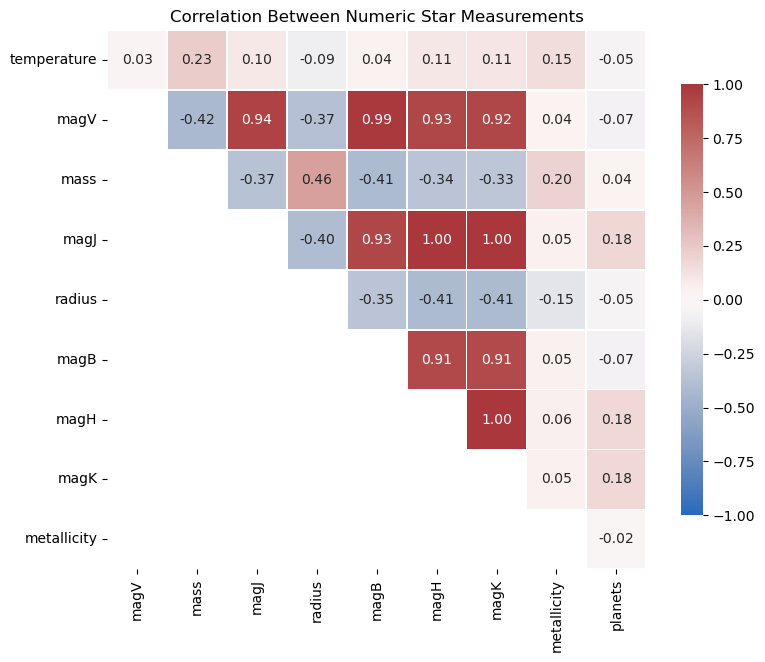

In [8]:
# Select numeric columns.
numeric_stars = stars.select_dtypes(include="number")
corr = numeric_stars.corr()

# Trim empty row and column.
trimmed = corr.iloc[:-1, 1:]

# Mask lower-left but keep new diagonal.
mask = np.tril(np.ones_like(trimmed, dtype=bool), k=-1)

# Plot heatmap.
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(
    trimmed, mask=mask, annot=True, fmt=".2f", center=0, vmin=-1, vmax=1,
    cmap="vlag", square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax,
)
ax.set_title("Correlation Between Numeric Star Measurements");

**My notes:**
- There are 3,183 stars and 12 columns, 10 of them numeric. `temperature` is the target, which leaves 9 regressors.
- There is considerable missing data. `magB` is missing in 2,180 rows (68%), `magV` in 1,909, `magH` in 1,627, `magJ` in 1,620, `magK` in 1,598, `metallicity` in 772, and the target `temperature` in 390. Only `name` and `planets` are complete. Using only observations with all readings would make for a small sample.
- Temperature runs from 485 K to 57,000 K. The 57,000 K entry is NN Ser A, spectral type DAO1, which is a white dwarf, so that's likely a real observation. The 485 K entry is KELT-2B, listed as spectral type K2V, and a K2V star should be around 3,900–5,300 K according to [Wikipedia](https://en.wikipedia.org/wiki/Stellar_classification). That one looks like a bad record, but I'm not an astronomer.
- The magnitude columns are mostly redundant. They're brightness measurements in different wavelength bands of the same stars. This means that the regression coefficients in part (d) will be unstable. In other words, refitting the model on resamples of the data will yield drastically different coefficients and yet make very similar predictions.
- No single regressor correlates strongly with temperature. The best is `mass` at 0.23, then `metallicity` at 0.15, then the magnitudes around 0.10. The eventual R<sup>2</sup> of 0.88 is a surprise and reminds me multiple regression is more than just the sum of regressors.

## Parts (a)–(b): Build the model on 75% of the data

**Function notes:**
- The exercise says all the numeric columns, so I let `select_dtypes` pick them instead of writing out a list. That keeps `magH`, which the textbook solution leaves out. I show the book's version at the end of the exercise for comparison.
- `.dropna()` is absolutely pivotal. scikit-learn's `LinearRegression` doesn't take NaN, so the rows have to be removed (**3,183 rows down to 596**).
- `data.pop("temperature")` removes `temperature` from `data`.
- `train_test_split(test_size=0.25, random_state=0)` gives exactly the 75% training share the exercise requests. Stratification would only be useful for *class* proportions.
- `LinearRegression()` is ordinary least squares solved with linear algebra. There's no `random_state`.
- There's no scaler. Standardizing is just a change of units, so it leaves the predictions, residuals, RMSE, and R<sup>2</sup> the same. Part (d) asks for the intercept, and that's best communicated in the original units.

In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

# All numeric columns, but remove observations with missing data.
star_data = stars.select_dtypes(include="number").dropna()

# pop() returns the target and removes it from the frame in one step.
y_stars = star_data.pop("temperature")
X_stars = star_data

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_stars, y_stars, test_size=0.25, random_state=0
)

lm = LinearRegression().fit(X_train_s, y_train_s)

print(f"rows in file:          {stars.shape[0]:>6,}")
print(f"rows after dropna():   {len(star_data):>6,}  ({len(star_data) / stars.shape[0]:.1%} kept)")
print(f"training rows (75%):   {len(X_train_s):>6,}")
print(f"test rows (25%):       {len(X_test_s):>6,}")
print(f"regressors:            {X_stars.shape[1]:>6}  -> {list(X_stars.columns)}")
print()
print(f"temperature range, full column: {stars.temperature.min():,.0f} K to {stars.temperature.max():,.0f} K")
print(f"temperature range, model rows:  {y_stars.min():,.0f} K to {y_stars.max():,.0f} K")

rows in file:           3,183
rows after dropna():      596  (18.7% kept)
training rows (75%):      447
test rows (25%):          149
regressors:                 9  -> ['magV', 'mass', 'magJ', 'radius', 'magB', 'magH', 'magK', 'metallicity', 'planets']

temperature range, full column: 485 K to 57,000 K
temperature range, model rows:  2,904 K to 11,327 K


**My notes:**
- 596 complete rows, split into 447 for training and 149 for testing.
- `dropna()` changed interpretation significantly. The full temperature column spans 485 K to 57,000 K, but the 596 remaining rows only span 2,904 K to 11,327 K. The model I'm scoring is a model of ordinary, well-observed stars. That's reasonable, but it should be said explicitly.
- The missing rows are not random. For example, a brown dwarf is faint and hard to measure in five bands, so it's easy to have missing data for it.

## Part (c): R<sup>2</sup> and RMSE

**Function notes:**
- `.score` returns different metrics depending on the estimator it's called on. For example, running `.score()` on a logistic regression returns *mean accuracy*. Here on a linear regression, it returns *R<sup>2</sup>*.
- There's no `rmse()` function in scikit-learn 0.23, so RMSE is `np.sqrt(mean_squared_error(...))`. You could also use `mean_squared_error(..., squared=False)`, but taking the square root makes the units more explicit.
- RMSE is in the target's units, so it's readable. The mean absolute error (MAE) is 180 K, but RMSE counts big errors more. R<sup>2</sup> is unitless and tells you the share of variance explained.
- I also report training R<sup>2</sup> and `adjusted_r2()` from `ml_utils.regression`. Plain R<sup>2</sup> only increases as you add regressors, when it's measured on the data you fit on. So, the training pair is the meaningful comparison. I include the adjusted test R<sup>2</sup> to confirm they move together.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from ml_utils.regression import adjusted_r2

star_preds = lm.predict(X_test_s)

print(f"R^2  (test):             {lm.score(X_test_s, y_test_s):.4f}")
print(f"R^2  (train):            {lm.score(X_train_s, y_train_s):.4f}")
print(f"adjusted R^2 (test):     {adjusted_r2(lm, X_test_s, y_test_s):.4f}")
print(f"adjusted R^2 (train):    {adjusted_r2(lm, X_train_s, y_train_s):.4f}")
print()
print(f"RMSE (np.sqrt):          {np.sqrt(mean_squared_error(y_test_s, star_preds)):,.2f} K")
print(f"MAE:                     {mean_absolute_error(y_test_s, star_preds):,.2f} K")
print(f"mean test temperature:   {y_test_s.mean():,.2f} K")
print(f"RMSE as % of that mean:  {np.sqrt(mean_squared_error(y_test_s, star_preds)) / y_test_s.mean():.2%}")

R^2  (test):             0.8802
R^2  (train):            0.8366
adjusted R^2 (test):     0.8725
adjusted R^2 (train):    0.8332

RMSE (np.sqrt):          257.94 K
MAE:                     179.54 K
mean test temperature:   5,468.31 K
RMSE as % of that mean:  4.72%


**My notes:**
- R<sup>2</sup> is 0.880 on the test set, which means the model explains about 88% of the variance in temperature among these stars. RMSE is **258 K**, which is roughly 4.7% of the average test temperature of 5,468 K.
- The test R<sup>2</sup> (0.880) is higher than the training R<sup>2</sup> (0.837). Usually, it's the other way around, but this split just happened to make for an easier test set.
- Adjusted R<sup>2</sup> is 0.873 on the test set against 0.880 unadjusted. It's a small difference, which means the 9 regressors aren't badly out of proportion to the sample size. Part (d) still shows some to be redundant.
- RMSE is easier to explain. You can say: "the model is typically off by a few hundred degrees." R<sup>2</sup> "explains 88% of the variance" is denser for someone non-technical.

## Part (d): Coefficients and intercept

**Function notes:**
- Neither `lm.coef_` nor `lm.intercept_` have feature names, so I put them back here.
- The magnitudes are not directly comparable across rows, because the regressors are on different scales.
- I add each regressor's range next to its coefficient, because its size is only relative to how much it moves.

In [11]:
# Reattach the feature names to the coefficient array.
coefficients = pd.DataFrame({
    "coefficient": lm.coef_,
    "regressor range": [f"{X_stars[c].min():.2f} to {X_stars[c].max():.2f}" for c in X_stars.columns],
}, index=X_stars.columns)

print(f"Intercept: {lm.intercept_:,.3f} K")
coefficients.reindex(coefficients.coefficient.abs().sort_values(ascending=False).index).round(3)

Intercept: 6,646.673 K


,coefficient,regressor range
magK,1531.794,-1.49 to 15.48
magJ,-990.333,-1.15 to 15.80
magB,-328.057,0.72 to 19.86
mass,276.081,0.09 to 3.09
magV,-174.253,0.01 to 17.94
planets,-29.174,0.00 to 9.00
magH,-6.004,-1.38 to 20.21
metallicity,-5.046,-2.09 to 0.56
radius,4.455,0.11 to 51.10


**My notes:**
- The two biggest coefficients are near opposites. `magK` gets +1,532 and `magJ` gets −990, on columns that correlate at 0.998. Neither number means much. If I dropped either column, the other's coefficient would change completely while R<sup>2</sup> wouldn't move much.
- The coefficients don't explain much. The model is good at predicting, but saying something like "each unit of magK adds 1,532 K" would be nonsense given how conflated the variables are.
- `magH` gets a coefficient of −6.0, which is close to zero. The textbook leaves it out, and keeping it only changes R<sup>2</sup> by 0.0001 (shown below).
- `radius` gets +4.5, which looks small, but it has a much bigger range than the magnitudes.
- The intercept of **6,647 K** is the predicted temperature when every regressor is set to zero. However, there's no star with zero mass, zero radius, and zero brightness, so the intercept is just for the model.

## Part (e): Visualize the residuals

**Function notes:**
- `plot_residuals(y_test, preds)` draws two panels: a scatterplot of each residual against its position in the test set, and a KDE of the residual distribution. It computes the residuals, so I just pass in the actuals and predictions.
- Ideally, I'm looking for residuals centered on zero, symmetric, with no pattern in the scatterplot.
- The x-axis of the left panel is observation order. That order is arbitrary, so it's there to spot clusters and outliers.

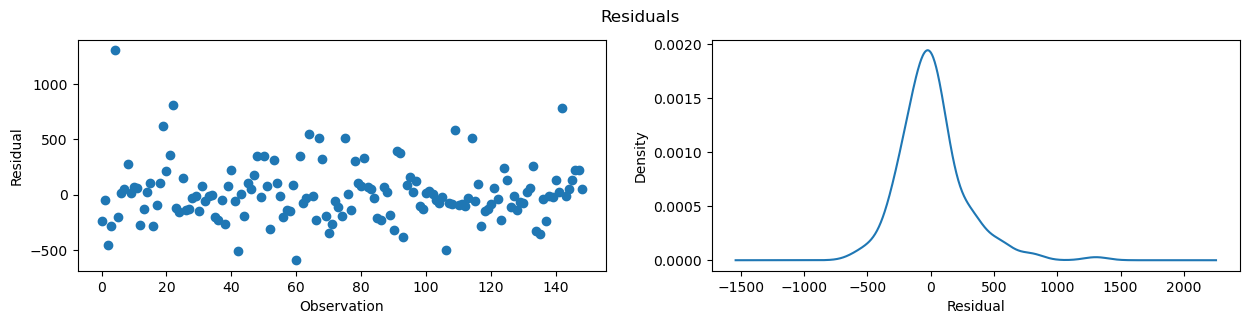

In [12]:
from ml_utils.regression import plot_residuals

axes = plot_residuals(y_test_s, star_preds)

In [13]:
# Summarize the residuals numerically.
residuals = y_test_s - star_preds
print(f"mean:              {residuals.mean():>9,.2f} K")
print(f"median:            {residuals.median():>9,.2f} K")
print(f"standard dev:      {residuals.std():>9,.2f} K")
print(f"min / max:         {residuals.min():>9,.2f} K / {residuals.max():,.2f} K")
print(f"|residual| > 500:  {(residuals.abs() > 500).sum():>9} of {len(residuals)}")
print(f"|residual| > 1000: {(residuals.abs() > 1000).sum():>9} of {len(residuals)}")

# The five worst misses.
worst = residuals.abs().sort_values(ascending=False).head(5).index
stars.loc[worst, ["name", "spectraltype", "temperature", "mass", "radius"]].assign(
    residual=residuals[worst].round(1)
)

mean:                  12.67 K
median:               -14.74 K
standard dev:         258.50 K
min / max:           -591.59 K / 1,304.80 K
|residual| > 500:         11 of 149
|residual| > 1000:         1 of 149


,name,spectraltype,temperature,mass,radius,residual
217,GAT 1370,M7.0 V,2904.0,0.089,0.1070,1304.8
102,CoRoT-3,F3V,6740.0,1.370,1.5600,806.9
243,Gliese 1214,M4.5,3250.0,0.176,0.2213,785.0
107,CoRoT-8,K1V,5080.0,0.880,0.7700,623.9
3002,WASP-10,K5,4675.0,0.710,0.7830,-591.6


**My notes:**
- The residuals are centered close to zero (mean +12.7 K, median −14.7 K) and the KDE is roughly symmetric with a single peak. This is what a well-behaved linear model should produce.
- One clear outlier at +1,305 K: GAT 1370, an M7.0 V red dwarf with 0.089 solar masses and a radius of 0.107. Its actual temperature is 2,904 K, which is the coldest star that we kept after calling `dropna()`. Like I mentioned before, the training data is mostly ordinary stars, so the model handles the extremes poorly.
- 11 of the 149 test stars miss by more than 500 K, and only that one misses by more than 1,000 K. The rest are clustered.
- The scatter shows no funnel and no curve. The variance stays constant across the range, which is what the model assumes, and there's no sign that we need to fit a nonlinear model.

### Comparison: dropping `magH`

**Function notes:** The book's solution uses an explicit column list that leaves out `magH`, so this block is here for parity with the textbook.

In [14]:
# The textbook's column list.
book_cols = ["metallicity", "temperature", "magJ", "radius", "magB", "magV", "magK", "mass", "planets"]
book_data = stars[book_cols].dropna()
y_book = book_data.pop("temperature")

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    book_data, y_book, test_size=0.25, random_state=0
)
lm_book = LinearRegression().fit(X_train_b, y_train_b)

pd.DataFrame({
    "rows": [len(star_data), len(book_data)],
    "regressors": [X_stars.shape[1], book_data.shape[1]],
    "R^2": [lm.score(X_test_s, y_test_s), lm_book.score(X_test_b, y_test_b)],
    "RMSE (K)": [
        np.sqrt(mean_squared_error(y_test_s, star_preds)),
        np.sqrt(mean_squared_error(y_test_b, lm_book.predict(X_test_b))),
    ],
    "intercept (K)": [lm.intercept_, lm_book.intercept_],
}, index=["all numeric (mine, incl. magH)", "textbook list (excl. magH)"]).round(4)

,rows,regressors,R^2,RMSE (K),intercept (K)
"all numeric (mine, incl. magH)",596,9,0.8802,257.9438,6646.6733
textbook list (excl. magH),596,8,0.8803,257.8945,6646.4817


**My notes:**
- The two models come out effectively identical: R<sup>2</sup> of 0.8802 versus 0.8803 and RMSE of 257.94 K versus 257.89 K.
- They also run on the same rows. The stars missing `magH` are almost entirely the same stars missing `magJ` and `magK`.

# Chapter 9, Exercise 3: Classify Planets with Shorter Years than Earth

> **a.** Using the `data/planets.csv` file, build a logistic regression model with the `eccentricity`, `semimajoraxis`, and `mass` columns as regressors. You will need to make a new column to use for the y (year shorter than Earth).
>
> **b.** Find the accuracy score.
>
> **c.** Use the `classification_report()` function from scikit-learn to see the precision, recall, and F1 score for each class.
>
> **d.** With the `plot_roc()` function from the `ml_utils.classification` module, plot the ROC curve.
>
> **e.** Create a confusion matrix using the `confusion_matrix_visual()` function from the `ml_utils.classification` module.

## Part (a): Build the target column and fit the model

**Function notes:**
- Earth is actually in this file, so I pull the value 365.2422 from the data instead of hardcoding.
- `planets.period < earth_period` returns a boolean Series, which scikit-learn uses for a binary target. Unfortunately, `NaN < x` evaluates to `False`, so the 164 planets with no recorded period get labeled "not shorter" rather than "unknown."
- Using the three specified regressors and calling `dropna()` takes 4,094 rows down to 1,234.
- I tried a `StandardScaler` pipeline and accuracy fell from 0.977 to 0.945. Standardizing shrinks `semimajoraxis` into the same range as the others, and the L2 penalty pushes down the coefficient that's doing work.
- `stratify=y` keeps the 2:1 True/False ratio in both halves. This is important for parts (b) and (c).
- The solar system check has an awkward syntax, because the column I want is named `list`.

In [15]:
from sklearn.linear_model import LogisticRegression

planets = pd.read_csv("data/planets.csv")

# Take the threshold from the data.
earth_period = planets.query('name == "Earth"').period.iat[0]
print(f"Earth's period in the data: {earth_period} days")

planets["shorter_year_than_earth"] = planets.period < earth_period
print()
print(planets.shorter_year_than_earth.value_counts())

# Drop to complete cases on the target and the three required regressors.
planet_data = planets[
    ["shorter_year_than_earth", "semimajoraxis", "mass", "eccentricity"]
].dropna()
y_planets = planet_data.pop("shorter_year_than_earth")
X_planets = planet_data

X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(
    X_planets, y_planets, test_size=0.25, random_state=0, stratify=y_planets
)

log_model = LogisticRegression(random_state=0).fit(X_train_p, y_train_p)

print()
print(f"rows in file:        {planets.shape[0]:>5,}")
print(f"rows after dropna(): {len(X_planets):>5,}  ({len(X_planets) / planets.shape[0]:.1%} kept)")
print(f"class balance:       {dict(y_planets.value_counts())}")
print(f"majority-class rate: {y_planets.mean():.4f}")
print(f"no recorded period:  {planets.period.isna().sum():>5,}")
print(f"  ...in model rows:  {planets.loc[X_planets.index].period.isna().sum():>5,}")

# Sanity check.
# Bracket indexing, not .query().
print()
print(planets[planets["list"] == "Solar System"][
    ["name", "period", "shorter_year_than_earth"]
].to_string(index=False))

Earth's period in the data: 365.2422 days

True     3481
False     613
Name: shorter_year_than_earth, dtype: int64

rows in file:        4,094
rows after dropna(): 1,234  (30.1% kept)
class balance:       {True: 821, False: 413}
majority-class rate: 0.6653
no recorded period:    164
  ...in model rows:     12

   name     period  shorter_year_than_earth
Mercury    87.9700                     True
  Venus   224.7000                     True
  Earth   365.2422                    False
   Mars   686.9800                    False
Jupiter  4332.8200                    False
 Saturn 10755.6700                    False
 Uranus 30687.1530                    False
Neptune 60190.0300                    False
  Pluto 90553.0200                    False


**My notes:**
- Across the file, 3,481 planets have shorter years than Earth and 613 don't.
- After `dropna()`, the balance shifts to 821 True and 413 False out of 1,234 rows, so the modeling set is 66.5% True instead of 85%.
- The baseline to compare is about 67%, because that's the majority-class rate. The accuracy in part (b) should be read against 67%.
- The solar system check confirms the label works: Mercury and Venus are True, and everything onward from Mars comes out False.

## Part (b): Accuracy score

**Function notes:**
- `log_model.score(X_test, y_test)` returns **accuracy** for a classifier. The estimator determines which statistic `score()` returns.
- I compute the majority-class rate alongside it, because accuracy doesn't mean much on an imbalanced target.

In [16]:
planet_preds = log_model.predict(X_test_p)

print(f"accuracy:                    {log_model.score(X_test_p, y_test_p):.4f}")
print(f"majority-class baseline:     {y_test_p.mean():.4f}")
print(f"improvement over baseline:   {log_model.score(X_test_p, y_test_p) - y_test_p.mean():.4f}")
print()
print(f"coefficients: {dict(zip(X_planets.columns, log_model.coef_[0].round(4)))}")
print(f"intercept:    {log_model.intercept_[0]:.4f}")

accuracy:                    0.9773
majority-class baseline:     0.6667
improvement over baseline:   0.3107

coefficients: {'semimajoraxis': -5.522, 'mass': 0.0268, 'eccentricity': -0.768}
intercept:    5.8877


**My notes:**
- **Accuracy is 0.9773**. The model gets 302 of the 309 test planets right.
- The coefficients are easy to read here. `semimajoraxis` gets **−5.52**, `mass` gets +0.027, and `eccentricity` gets −0.77. Because of the exaggerated scales between them, semi-major axis turns out to be the only real driver here.
- This tracks. According to [Wikipedia](https://en.wikipedia.org/wiki/Kepler%27s_laws_of_planetary_motion), Kepler's third law says the orbital period is determined by the semi-major axis and the star's mass.

## Part (c): Classification report

**Function notes:**
- `classification_report()` returns a **formatted string**, so it needs `print()`.
- It describes precision, recall, and F1 per class. An accuracy score wouldn't show that the model is better at predicting one class than the other.
- **Precision** is how often a prediction of that class was right, and **recall** is how much of that class the model actually found.
- For False, precision answers "when the model said this planet has a long year, was it correct?" and recall answers "of the planets that really have long years, how many did it catch?"
- `support` is the row count per class in the test set.

In [17]:
from sklearn.metrics import classification_report

print(classification_report(y_test_p, planet_preds))

              precision    recall  f1-score   support

       False       0.98      0.95      0.97       103
        True       0.98      0.99      0.98       206

    accuracy                           0.98       309
   macro avg       0.98      0.97      0.97       309
weighted avg       0.98      0.98      0.98       309



**My notes:**
- Both classes score 0.98 precision.
- Recall between them are different. The True class is 0.99 (204 of 206 found), while the False class hits 0.95 (98 of 103 found). Five long-year planets got called short and two short-year planets got called long.
- There're twice as many True examples, so long-year planets are a little harder to get right.
- The macro average (0.97) is below the weighted average (0.98), because it treats both classes as equally important, and the weighted version doesn't.
- F1 is the harmonic mean of precision and recall.

## Part (d): ROC curve

**Function notes:**
- `plot_roc(y_test, preds)` from `ml_utils.classification` needs **probabilities**.
- `predict_proba(X_test_p)[:, 1]` takes the second column. Column order follows `log_model.classes_`, which is `[False, True]`, so column 1 is P(shorter year). I print `classes_` rather than assume it.
- An ROC curve visualizes the decision threshold from 0 to 1 and plots true positive rate against false positive rate. The accuracy number in part (b) is the point at 0.5.
- The dashed diagonal represents a random coinflip.
- I also print **AUC**, the area under the curve, which rates the entire curve at once.

classes_: [False  True]
AUC: 0.9852


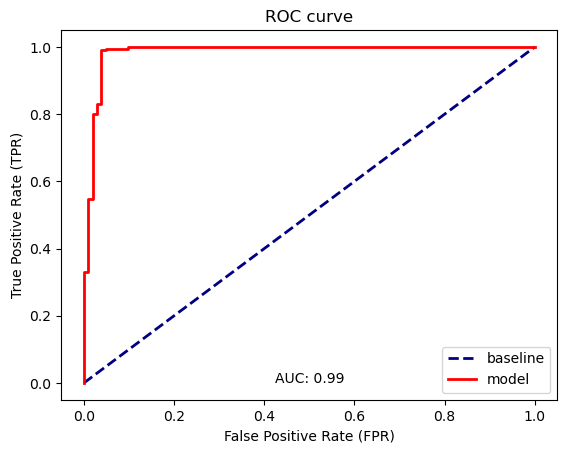

In [18]:
from ml_utils.classification import plot_roc
from sklearn.metrics import roc_auc_score

# Column order follows classes_, so column 1 is P(True).
print(f"classes_: {log_model.classes_}")
planet_probs = log_model.predict_proba(X_test_p)[:, 1]
print(f"AUC: {roc_auc_score(y_test_p, planet_probs):.4f}")

plot_roc(y_test_p, planet_probs);

**My notes:**
- **AUC is 0.985.** The curve climbs almost straight up, then turns sharply right around 0.05.
- Pick a random short-year planet and a random long-year planet, and the model gives the short-year one a higher probability 98.5% of the time.
- Because the curve hugs the corner, there's a wide band of thresholds that would produce nearly the same result.

## Part (e): Confusion matrix

**Function notes:**
- `confusion_matrix_visual(y_true, y_pred, class_labels)` from `ml_utils.classification` puts the `sklearn` confusion matrix in a seaborn heatmap. The plot is transposed, so it's important to read the axis labels.
- `class_labels` are applied in the sorted class order, which is `[False, True]`.
- `flip=True` reverses both the labels and the matrix so true positives land in the top-left corner, which I feel is more conventional.
- The counts are what matter, because color matters less with so few comparisons.

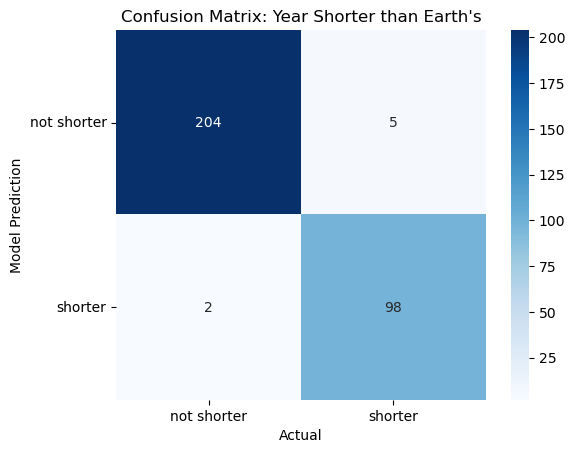

In [19]:
from ml_utils.classification import confusion_matrix_visual

# flip=True puts true positives in the top-left corner.
confusion_matrix_visual(
    y_test_p, planet_preds, ["shorter", "not shorter"], flip=True,
    title="Confusion Matrix: Year Shorter than Earth's",
);

The four cells of the matrix above, written out:

| | count |
| --- | ---: |
| True positives (short year, called short) | 204 |
| True negatives (long year, called long) | 98 |
| False positives (long year, called short) | 5 |
| False negatives (short year, called long) | 2 |

**My notes:**
- Seven errors in 309 test planets.
- The 5 errors on the long-year class out of 103 is where the 0.95 recall comes from, while the 2 errors out of 206 short-year planets give 0.99.

## Conclusion

**`.dropna()` made big decisions.** Exercise 2 started with 3,183 stars and ended with 596. Exercise 3 went from 4,094 planets to 1,234. In the star data, it also changed what the model is about. The surviving rows only span 2,904 K to 11,327 K, while the full column runs 485 K to 57,000 K. The stars with incomplete measurements are the faint and extreme ones, so those are the ones that got dropped. The R<sup>2</sup> of 0.88 describes *ordinary*, *well-observed stars*. That's fine to build, but it should be stated rather than being implied.

**Scaling isn't automatically good.** It was required in Exercise 1 for good reason. `total sulfur dioxide` ran from 6 to 440, which would have overwhelmed `density` with a range of 0.987 to 1.039. In Exercise 2, standardizing changes the coefficients but leaves the predictions and R<sup>2</sup> the same. In Exercise 3, adding a `StandardScaler` dropped accuracy from 0.977 to 0.945. I would have guessed scaling was always useful/"safe" before this.

**The metric has to match the model.** `score()` returned R<sup>2</sup> in Exercise 2 and accuracy in Exercise 3. It's the same method that gives a different statistic depending on the estimator you call it on. Accuracy wouldn't work in Exercise 1, because the cluster numbers are arbitrary. That's the reason to use the Fowlkes-Mallows Index, since it compares pairs. And in Exercise 3, accuracy is misleading. The accuracy of 0.9773 is compared to a baseline of 67%, not 0%.

**A model can predict well and explain nothing.** The star regression gave `magK` +1,532 and `magJ` −990. Those columns correlate at 0.998, and that's why they're given near opposite coefficients. Neither number means anything by itself, and the model is still accurate. Exercise 3 is a similar problem from the other direction. 97.7% accuracy on three orbital parameters is just Kepler's third law; it *does* mean something, but it's a reflection of a natural law.

**Missing data turns into an answer if you let it.** `NaN < 365.2422` returns `False`, not `NaN`. 12 planets with no recorded period got into the model and labeled "year not shorter than Earth's." The line of code looks fine, which is why it's worth checking.

## References

- Molin, S. (2021). *Hands-On Data Analysis with Pandas* (2nd ed.). Packt Publishing.
- Molin, S. (2021). *ml-utils* [Python package]. https://github.com/stefmolin/ml-utils
- scikit-learn 0.23.2 documentation: https://scikit-learn.org/0.23/
- pandas 1.2.0 documentation: https://pandas.pydata.org/pandas-docs/version/1.2.0/
- Stellar classification. *Wikipedia.* https://en.wikipedia.org/wiki/Stellar_classification
- Kepler's laws of planetary motion. *Wikipedia.* https://en.wikipedia.org/wiki/Kepler%27s_laws_of_planetary_motion
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems, 47*(4), 547–553. (Wine data via the UCI Machine Learning Repository.)
- Rein, H. (2012). *The Open Exoplanet Catalogue.* https://github.com/OpenExoplanetCatalogue/open_exoplanet_catalogue/ (Source of `stars.csv` and `planets.csv`.)